# Every box on the real slice (card #36)

jonas's scratch notebook. It runs each box of `main.ipynb` on real Companies House data instead of the tiny world, to see what works, what breaks and how long it takes.

**The data:** the query companies that part 1 of the 2021 crawl (#24) had finished when this ran. That is a fair sample of construction companies formed in 2021, not the final data; phantodevc counts part 2 separately in #62. The copy also holds the files of 25 companies formed in 2022 that the first small run fetched. None of them is labelled or counted, and the matcher learns only from pairs at companies formed by September 2021, so nothing below looks at the 2022 test set.

**Masking:** only display columns are shown. A director's name becomes a pseudonym, and birth dates never appear.

The notes under each box describe the run saved here: 438 query companies, the crawl's state at 15:04 on Saturday 14 November. A second key table, defined at 16:05 before it was run, follows the first, and the headline, defined at 18:58 before it was run, follows them. What breaks is listed at the end.

This project is a prototype and is not financial advice.

In [1]:
# Setup: pick up changes to src/ without restarting, and make `import src` work from notebooks/
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, "..")

import random
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import baseline, decide, evaluate, interface, real_slice, resolve
from src import evidence as ev
from src import ingest_companies_house as adapter

SEED = 42              # one seed for everything random, as in main.ipynb
random.seed(SEED)
np.random.seed(SEED)
COSTS = (10, 2, 1)     # the team's costs: a missed case, a wrong flag, asking
timings = {}           # seconds per step, shown at the end

## Data
`real_slice.load_slice()` reads the finished query companies from `data/raw/query_companies.csv` and runs the team's adapter over every raw file, with the schema checks. It keeps those companies as the slice, then labels and splits them with `label_failures` and `split`. Every other company in `data/raw` is a director's earlier company: evidence, never a query.

In [2]:
start = time.perf_counter()
with warnings.catch_warnings(record=True) as caught:   # print the adapter's warnings without a file path
    warnings.simplefilter("always")
    mentions, claims, labels, left_out = real_slice.load_slice()
timings["load the slice: adapter, checks, labels"] = time.perf_counter() - start
assert not (labels["split"] == "test").any(), "2022 companies are in the slice: keep them out until the test run"
for warning in caught:
    print("adapter warning:", warning.message)

print("mentions:", mentions["kind"].value_counts().to_dict(), "| claims:", len(claims))
print("query companies labelled:", len(labels), "| left out:", left_out if left_out else "none")
print("formed between", labels["formed_on"].min(), "and", labels["formed_on"].max())

# The team's label (insolvent or dissolved within 24 months), and insolvency only (count_dissolved=False)
labels["failed_insolvency"] = evaluate.label_failures(mentions, count_dissolved=False).loc[labels["company_id"]].to_numpy()
train = labels[labels["split"] == "train"]
validation = labels[labels["split"] == "validation"]
labels.groupby("split").agg(companies=("company_id", "size"), failed=("failed", "sum"),
                            share_failed=("failed", "mean"),
                            failed_through_insolvency=("failed_insolvency", "sum")).round(3)

adapter warning: 2 director records skipped: the resignation is dated before the appointment.
mentions: {'company': 4621, 'person': 2990} | claims: 2990
query companies labelled: 438 | left out: none
formed between 2021-01-02 and 2021-12-31


,companies,failed,share_failed,failed_through_insolvency
split,,,,
train,331,111,0.335,0
validation,107,26,0.243,0


**What it shows.** All 438 query companies could be labelled. Under the team's label, 111 of 331 failed in train and 26 of 107 in validation, and **none through liquidation or administration**: on this sample the label is dissolution only. Validation fails less often than train (24% against 34%), which matters for the line below.

## Baselines, on validation
The three baselines decide for the validation companies (formed Oct–Dec 2021), and `score_methods` scores them all the same way. A baseline flags a company when one of its directors is linked to a company that went insolvent in the 3 years before it was formed.

In [3]:
start = time.perf_counter()
baseline_decisions = baseline.run_all(list(validation["company_id"]), mentions, claims)
timings["three baselines on validation"] = time.perf_counter() - start
evaluate.score_methods(baseline_decisions, validation)

,method,companies,failed,flags,false_flags,misses,precision,recall,not_enough_evidence,pr_auc
0,flag_nothing,107,26,0,0,26,NaN,0.000000,0.0,None
1,same_name,107,26,2,1,25,0.5,0.038462,0.0,None
2,officer_links,107,26,0,0,26,NaN,0.000000,0.0,None


In [4]:
# The same baselines with no 3-year window (100 years), to compare with the decision layer, which has none
no_window = baseline.run_all(list(validation["company_id"]), mentions, claims, window_years=100)
evaluate.score_methods(no_window, validation)[["method", "flags", "false_flags", "misses", "precision", "recall"]]

,method,flags,false_flags,misses,precision,recall
0,flag_nothing,0,0,26,NaN,0.000000
1,same_name,12,9,23,0.25,0.115385
2,officer_links,6,6,26,0.00,0.000000


**What it shows.** With their 3-year window, `same_name` flags 2 validation companies (1 of them failed) and `officer_links` flags none. With no window, `officer_links` flags 6, all of them false flags, and `same_name` flags 12, 9 of them false. The decision layer has no window, so the baselines and our method don't yet judge by the same rule.

## Blocking (#83)
Two person records are a candidate pair when they have the same surname and first initial, or the same birth month and year and a similar surname. The card's bar: under a minute on the real slice.

In [5]:
start = time.perf_counter()
candidates = resolve.candidate_pairs(mentions)
timings["blocking (#83)"] = time.perf_counter() - start

people = int((mentions["kind"] == "person").sum())
print(f"{len(candidates)} candidate pairs out of {people * (people - 1) // 2} possible, "
      f"from {people} person records, in {timings['blocking (#83)']:.2f} s")

2586 candidate pairs out of 4468555 possible, from 2990 person records, in 0.06 s


## Blocking recall, on validation (#85)
The true pairs are the register's own links: two records with the same officer id. A pair counts as validation when one of its two people is a director of a validation company (`real_slice.pair_split`), so no validation pair is ever learned from.

In [6]:
splits = real_slice.person_split(mentions, claims, labels)   # each person record's split, from the company they direct
true_pairs = pd.DataFrame(sorted(resolve.officer_pairs(mentions)), columns=["a", "b"])
proposed = set(zip(candidates["a"], candidates["b"]))        # blocking lists each pair once, with a < b, like officer_pairs

for name in ["train", "validation"]:
    part = true_pairs[real_slice.pair_split(true_pairs, splits) == name]
    kept = sum(pair in proposed for pair in zip(part["a"], part["b"]))
    print(f"{name}: blocking kept {kept} of {len(part)} same-officer-id pairs ({kept / len(part):.1%})")
print("all pairs, with the team's blocking_recall:", resolve.blocking_recall(candidates, mentions))

train: blocking kept 1490 of 1491 same-officer-id pairs (99.9%)
validation: blocking kept 45 of 45 same-officer-id pairs (100.0%)
all pairs, with the team's blocking_recall: {'true_pairs': 1536, 'kept': 1535, 'recall': 0.9993489583333334}


**What it shows.** Blocking proposes 2,586 of the 4,468,555 possible pairs in well under a second, far inside the card's minute (#83). It keeps all 45 same-officer-id pairs in validation and 1,490 of 1,491 in train (#85), so the rule doesn't need loosening.

## The matcher (#31)
The labelled pairs: the same officer id is label 1, and a candidate pair with different officer ids is label 0. The matcher learns from the training pairs only, and only from pairs whose two records are at companies formed by September 2021: a record at a later company, labelled or not, keeps its pair out, so no record from the validation period or from 2022 trains it. The officer id is the label, never a feature.

In [7]:
start = time.perf_counter()
labelled = resolve.labelled_pairs(mentions)
labelled["split"] = real_slice.pair_split(labelled, splits)
# The matcher learns only from pairs whose two records are at companies formed by the end of the
# training period: a record at a later company, labelled or not (2022 included), keeps its pair out
later = (labelled["split"] == "train") & ~real_slice.train_period_pairs(labelled, mentions, claims)
labelled.loc[later, "split"] = "left out"
train_pairs = labelled[labelled["split"] == "train"].reset_index(drop=True)
model = resolve.train_matcher(resolve.pair_features(train_pairs, mentions), train_pairs["label"], SEED)
timings["matcher: labelled pairs, features, training"] = time.perf_counter() - start

print(pd.crosstab(labelled["split"], labelled["label"]).rename(columns={0: "label 0", 1: "label 1"})
      .reindex(["train", "validation"]))
resolve.matcher_weights(model).round(2)

label       label 0  label 1
split                       
train           952     1470
validation       58       45

name_similarity        2.43
name_missing           0.00
birth_same             4.22
birth_missing         -0.12
postcode_same          1.94
postcode_missing       0.31
nationality_same       2.16
nationality_missing    0.00
intercept             -8.34
dtype: float64

## Calibration, on validation (#88)
Is `p` a probability? Among validation pairs given about 0.6, about 60% should have the same officer id. The Brier score is the mean of (p − label)²: 0 is perfect, and always answering the training share of label 1 is the bar to beat.

In [8]:
held_out = labelled[labelled["split"] == "validation"].reset_index(drop=True)
p = np.asarray(resolve.match_probability(model, resolve.pair_features(held_out, mentions)))
y = held_out["label"].to_numpy()

brier = np.mean((p - y) ** 2)
bar = np.mean((train_pairs["label"].mean() - y) ** 2)
print(f"Brier score on {len(held_out)} validation pairs: {brier:.3f} (always the training share of label 1: {bar:.3f})")

bins = pd.cut(p, [0, 0.2, 0.4, 0.6, 0.8, 1.0], include_lowest=True)
reliability = (pd.DataFrame({"p": p, "same officer id": y})
               .groupby(bins, observed=True)
               .agg(pairs=("p", "size"), mean_p=("p", "mean"), same_officer_id=("same officer id", "sum")))
reliability["share with 95% interval"] = [real_slice.rate(int(k), int(n)) for k, n in
                                          zip(reliability["same_officer_id"], reliability["pairs"])]
reliability.round(2)

Brier score on 103 validation pairs: 0.124 (always the training share of label 1: 0.275)


,pairs,mean_p,same_officer_id,share with 95% interval
"(-0.001, 0.2]",43,0.01,0,0 of 43: 0% (0-8%)
"(0.4, 0.6]",1,0.47,1,1 of 1: 100% (21-100%)
"(0.6, 0.8]",27,0.61,20,20 of 27: 74% (55-87%)
"(0.8, 1.0]",32,0.92,24,24 of 32: 75% (58-87%)


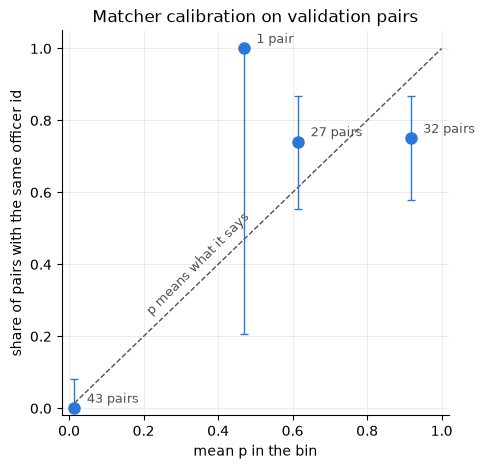

In [9]:
# The reliability plot: one dot per bin, with its 95% interval. On the dashed line, p means what it says.
share = reliability["same_officer_id"] / reliability["pairs"]
ends = [real_slice.wilson(int(k), int(n)) for k, n in zip(reliability["same_officer_id"], reliability["pairs"])]
below = [middle - low for middle, (low, high) in zip(share, ends)]
above = [high - middle for middle, (low, high) in zip(share, ends)]

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, color="#52514e")
ax.errorbar(reliability["mean_p"], share, yerr=[below, above], fmt="o", markersize=8, color="#2a78d6",
            elinewidth=1, capsize=3, zorder=3)
for x, middle, n in zip(reliability["mean_p"], share, reliability["pairs"]):
    ax.annotate(f"{n} pair" + ("s" if n != 1 else ""), (x, middle), textcoords="offset points",
                xytext=(9, 4), fontsize=9, color="#52514e")
ax.text(0.2, 0.26, "p means what it says", rotation=45, fontsize=9, color="#52514e")
ax.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.05), xlabel="mean p in the bin",
       ylabel="share of pairs with the same officer id", title="Matcher calibration on validation pairs")
ax.grid(color="#e5e4e0", linewidth=0.5)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**What it shows.** The weights make sense: agreeing on birth month and year counts most, then name, nationality and postcode district. `p` is right where it is low: 43 pairs under 0.2, none with the same officer id. Around 0.61 it holds (20 of 27, interval 55–87%). At the top it is **too sure**: 32 pairs with a mean `p` of 0.92, of which only 24 share an officer id (75%, interval 58–87%). Part of that gap may be the label rather than the matcher: two records that agree on name, birth, postcode and nationality but carry two officer ids may be one person the register split. The Brier score, 0.124, beats the bar of 0.275. With 103 validation pairs this is a first check, not a verdict, and `p` doesn't pass yet: by #88's rule it is a score, not a probability, until the hand check (#89) says more.

## The failure line (#33, #94)
Every candidate pair gets the matcher's `p`. For each company, `candidate_matches` keeps the pairs that tie one of its directors to someone who ran a company insolvent by its formation date, and P(predecessor) = 1 − ∏(1 − p). The straight line from P(predecessor) to the failure rate is fitted on the training companies only.

In [10]:
start = time.perf_counter()
scored = resolve.scored_pairs(model, candidates, mentions)
matches = {query: decide.candidate_matches(query, mentions, claims, scored) for query in labels["company_id"]}
p_pred = pd.Series({query: decide.company_p_predecessor(found) for query, found in matches.items()})
timings["matches and P(predecessor), every company"] = time.perf_counter() - start

print("P(predecessor) = 0:", int((p_pred == 0).sum()), "| above 0:", int((p_pred > 0).sum()),
      "| 0.5 or more:", int((p_pred >= 0.5).sum()), "| no director records:", int(p_pred.isna().sum()))

line = decide.fit_failure_line(p_pred.loc[train["company_id"]], train["failed"])
clear_below, flag_above = decide.thresholds(*COSTS)
print(f"the line, fitted on {len(train)} training companies: {line[0]:.1%} fail without an insolvent predecessor, "
      f"{line[1]:.1%} with one")
print(f"the costs {COSTS}: CLEAR at or below {clear_below:.0%}, FLAG at or above {flag_above:.0%}")
print("rate_with is below the FLAG threshold: FLAG can never fire" if line[1] < flag_above else "FLAG can fire")

P(predecessor) = 0: 361 | above 0: 77 | 0.5 or more: 31 | no director records: 0
the line, fitted on 331 training companies: 35.0% fail without an insolvent predecessor, 9.6% with one
the costs (10, 2, 1): CLEAR at or below 10%, FLAG at or above 50%
rate_with is below the FLAG threshold: FLAG can never fire


In [11]:
# 94: on validation, the line's prediction next to the real failure rate, in three groups of P(predecessor)
line_check = pd.DataFrame({"p_predecessor": p_pred.loc[validation["company_id"]].to_numpy(),
                           "failed": validation["failed"].to_numpy()})
line_check["predicted"] = [decide.p_fail(p, line) for p in line_check["p_predecessor"]]
groups = pd.cut(line_check["p_predecessor"], [-0.01, 0, 0.5, 1], labels=["0", "above 0, up to 0.5", "above 0.5"])
summary = line_check.groupby(groups, observed=True).agg(
    companies=("failed", "size"), failed=("failed", "sum"), predicted=("predicted", "mean"))
summary["really failed, with 95% interval"] = [real_slice.rate(int(k), int(n)) for k, n in zip(summary["failed"], summary["companies"])]
summary.round(2)

,companies,failed,predicted,"really failed, with 95% interval"
p_predecessor,,,,
0,91,23,0.35,23 of 91: 25% (17-35%)
"above 0, up to 0.5",7,2,0.34,2 of 7: 29% (8-64%)
above 0.5,9,1,0.13,1 of 9: 11% (2-44%)


**What it shows.** The line slopes **down**: 35.0% of training companies without an insolvent predecessor fail, against 9.6% at P(predecessor) = 1. So a likely predecessor *lowers* P(fail), and `rate_with` is below the FLAG threshold of 50%: **FLAG can never fire**, which #94 says to raise on the call. Validation points the same way, but on 9 companies: 1 of 9 failed above 0.5 (11%, interval 2–44%), against 23 of 91 at 0 (25%, 17–35%). The line also predicts 35% where validation shows 25%, because validation fails less often than train.

## The decision layer, on validation
FLAG, CLEAR or NOT ENOUGH EVIDENCE for each validation company, with the line above and the team's costs, scored next to the baselines by the same function.

In [12]:
start = time.perf_counter()
our_decisions = pd.DataFrame([decide.decide(query, matches[query], line, COSTS) for query in validation["company_id"]],
                             columns=ev.DECISION_COLS)
timings["decision layer on validation"] = time.perf_counter() - start

print(our_decisions["decision"].value_counts().to_dict())
print(f"share of validation companies that failed: {validation['failed'].mean():.3f} (what a PR-AUC with no signal gives)")
evaluate.score_methods(pd.concat([baseline_decisions, our_decisions], ignore_index=True), validation)

{'NOT ENOUGH EVIDENCE': 106, 'CLEAR': 1}
share of validation companies that failed: 0.243 (what a PR-AUC with no signal gives)


,method,companies,failed,flags,false_flags,misses,precision,recall,not_enough_evidence,pr_auc
0,flag_nothing,107,26,0,0,26,NaN,0.000000,0.000000,NaN
1,same_name,107,26,2,1,25,0.5,0.038462,0.000000,NaN
2,officer_links,107,26,0,0,26,NaN,0.000000,0.000000,NaN
3,formula,107,26,0,0,26,NaN,0.000000,0.990654,0.253317


**What it shows.** 106 of 107 validation companies get NOT ENOUGH EVIDENCE, and the one CLEAR is the company with the likeliest predecessor (below). The code does what it says; the numbers don't fit together. The label puts about a third of companies in "failed", and the line puts a company with no predecessor at 35%, between CLEAR at 10% and FLAG at 50%, so it can only land in between. The PR-AUC of 0.253 is about what no signal gives (0.243), and of the 26 failures only `same_name` catches one.

## show() for one real company
The validation company with the highest P(predecessor). Directors are pseudonyms; company names are shown, as the adapter's masking allows (#111).

13668751: CLEAR
13668751 may share a director with 03250164, an earlier company that went insolvent (92% sure it's the same person): its 10% chance of failing within two years is low enough to clear.


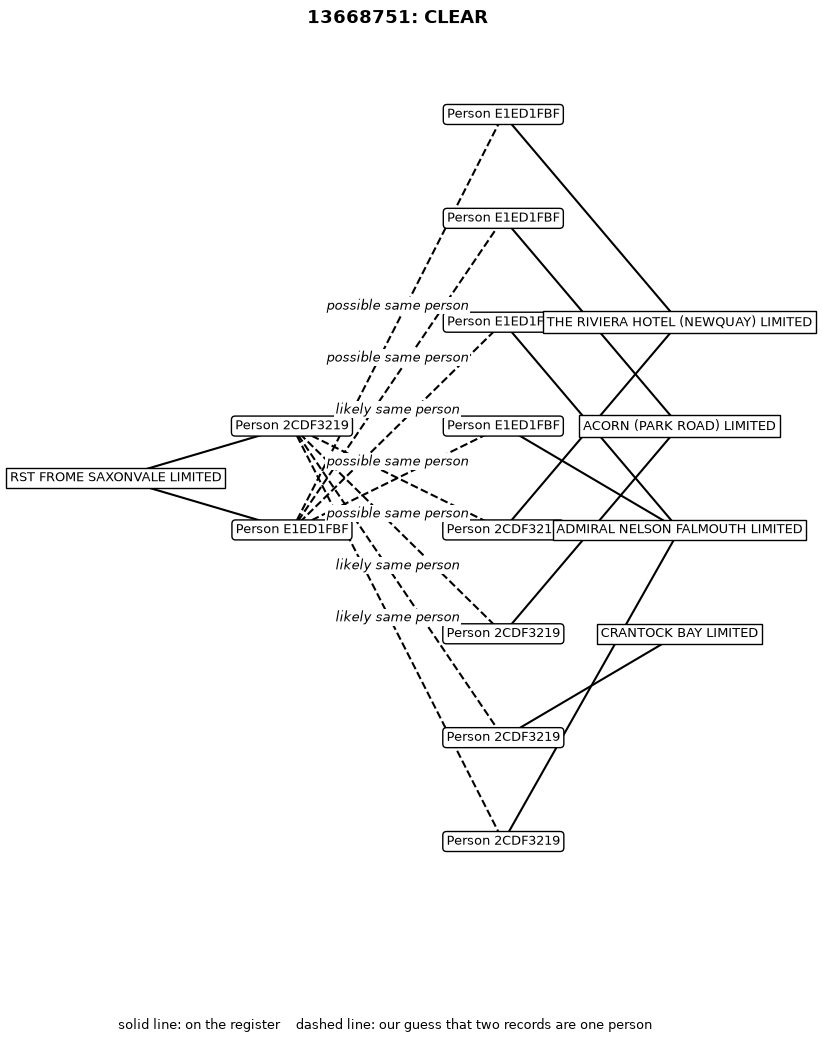

,line,from,to,says,how sure,p,source,record or depends on,check first
0,solid (fact),Person 2CDF3219,RST FROME SAXONVALE LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/13668751.json#0@8d864f8bdf13...,
1,solid (fact),Person E1ED1FBF,RST FROME SAXONVALE LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/13668751.json#1@8d864f8bdf13...,
2,solid (fact),Person E1ED1FBF,THE RIVIERA HOTEL (NEWQUAY) LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/06328919.json#1@89c11fdca5f1...,
3,solid (fact),Person E1ED1FBF,ACORN (PARK ROAD) LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/06032661.json#1@278743b34149...,
4,solid (fact),Person E1ED1FBF,ADMIRAL NELSON FALMOUTH LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/03250164.json#1@9c76726efaec...,
5,solid (fact),Person E1ED1FBF,ADMIRAL NELSON FALMOUTH LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/03250164.json#7@9c76726efaec...,
6,solid (fact),Person 2CDF3219,THE RIVIERA HOTEL (NEWQUAY) LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/06328919.json#3@89c11fdca5f1...,
7,solid (fact),Person 2CDF3219,ACORN (PARK ROAD) LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/06032661.json#4@278743b34149...,
8,solid (fact),Person 2CDF3219,CRANTOCK BAY LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/07831175.json#0@9b4632300fc0...,
9,solid (fact),Person 2CDF3219,ADMIRAL NELSON FALMOUTH LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/03250164.json#6@9c76726efaec...,


In [13]:
example = p_pred.loc[validation["company_id"]].sort_values(ascending=False, kind="stable").index[0]
start = time.perf_counter()
row, fig, table = interface.show(example, mentions, claims, matches, our_decisions)
timings["show() for one company"] = time.perf_counter() - start

**What it shows.** Both directors of this company match records at insolvent earlier companies (`p` 0.61 and 0.92), and the decision is CLEAR, because the line says such companies fail less. Two things in the picture don't work yet on real data: with 8 guesses the labels overlap, and both ends of a guess show the same pseudonym, because the same name always gets the same pseudonym.

## The key table: does an insolvent predecessor raise the failure rate?
Every labelled company (train and validation; there is no test set yet), counted once, under the strongest link it has to an insolvent earlier company. The rule is the decision layer's: a director on record when the company was formed, paired with someone who was a director of a company insolvent by that date, with no time window. Each rate has its 95% Wilson interval.

In [14]:
start = time.perf_counter()
links = real_slice.link_pairs(mentions)
strongest = real_slice.strongest_link(labels["company_id"], mentions, claims, links)
timings["key table"] = time.perf_counter() - start

by_company = labels.set_index("company_id")
real_slice.rate_table(strongest, by_company["failed"], by_company["failed_insolvency"])

,strongest link,companies,failed (team label),failed through insolvency only
0,no predecessor,369,120 of 369: 33% (28-37%),0 of 369: 0% (0-1%)
1,same officer id,13,2 of 13: 15% (4-42%),0 of 13: 0% (0-23%)
2,same name and birth month and year,17,2 of 17: 12% (3-34%),0 of 17: 0% (0-18%)
3,same name only,39,13 of 39: 33% (21-49%),0 of 39: 0% (0-9%)


In [15]:
# The two links that point to the same person, taken together, and where the links fall by split
together = strongest.index[strongest.isin(["same officer id", "same name and birth month and year"])]
print("same officer id, or same name and birth month and year, together:",
      real_slice.rate(int(by_company.loc[together, "failed"].sum()), len(together)))
pd.crosstab(strongest.rename("strongest link"), by_company["split"])

same officer id, or same name and birth month and year, together: 4 of 30: 13% (5-30%)


split,train,validation
strongest link,,
no predecessor,275,94
same name and birth month and year,14,3
same name only,35,4
same officer id,7,6


**What it shows. No sign of it on this sample: the rate is lower, not higher.** Companies with a predecessor under the same officer id failed 2 of 13 times, and under the same name and birth month and year 2 of 17. Together that is 4 of 30 (13%, interval 5–30%), against 120 of 369 (33%, 28–37%) with no predecessor. The two intervals overlap only a little (28–30%), so the drop could still be chance. Same-name-only links, probably mostly namesakes, fail like companies with no predecessor (13 of 39, 33%). Through liquidation or administration, not one company in any row failed within 24 months, so the question the project asks, about insolvency, has no answer on this sample yet.

Where these counts could be wrong: the crawl reads each officer's first 50 appointments, and per director only the first 100 name-search results and at most 20 same-name officers, so some predecessors are never seen; a link by name and birth month and year can still be two people; and there is no time window, so an insolvency long before the company was formed counts too.

## The second key table: predecessors that failed the way our label defines failure
Defined before it was run on any real data (commit 469c621, 16:05). An earlier company counts as a predecessor only if it failed the way our label defines failure: liquidation, administration or dissolution within 24 months of its own incorporation. That failure must be dated on or before the new company's formation date, the as-of rule of the first table. Same companies, labels, links, columns and 95% intervals as the first table.

The links come from the directors' saved appointment lists, not the officer lists: the crawl saved an officer list only for a query company or a company with an insolvency history, so a predecessor that was only dissolved has none. Two checks were fixed with the definition: (a) the same route with the first table's rule should give the first table again; (b) how many companies change if a failure on the formation day itself doesn't count.

In [16]:
start = time.perf_counter()
appointments = real_slice.appointment_rows(adapter.load_raw())   # every directorship in the saved appointment lists
failed_on = real_slice.failure_dates(mentions)
assert (failed_on.notna() == evaluate.label_failures(mentions)).all()   # failed exactly when the team's label says so
strongest_failed = real_slice.strongest_failed_link(labels["company_id"], mentions, claims, appointments, failed_on)
timings["second key table"] = time.perf_counter() - start

print(f"{len(appointments)} directorships in {appointments['officer_id'].nunique()} appointment lists; "
      f"{int(failed_on.notna().sum())} of {len(failed_on)} companies on file failed under our label")
first = real_slice.rate_table(strongest, by_company["failed"], by_company["failed_insolvency"]).set_index("strongest link")
second = real_slice.rate_table(strongest_failed, by_company["failed"], by_company["failed_insolvency"]).set_index("strongest link")
pd.concat([first, second], axis=1, keys=["first table: an insolvent predecessor",
                                         "second table: a predecessor that failed under our label"])

7159 directorships in 2976 appointment lists; 1004 of 4621 companies on file failed under our label


first table: an insolvent predecessor  \
                                                               companies   
strongest link                                                             
no predecessor                                                       369   
same officer id                                                       13   
same name and birth month and year                                    17   
same name only                                                        39   

                                                              \
                                         failed (team label)   
strongest link                                                 
no predecessor                      120 of 369: 33% (28-37%)   
same officer id                         2 of 13: 15% (4-42%)   
same name and birth month and year      2 of 17: 12% (3-34%)   
same name only                        13 of 39: 33% (21-49%)   

                                                                   \
                                   failed through insolvency only   
strongest link                                                      
no predecessor                                0 of 369: 0% (0-1%)   
same officer id                               0 of 13: 0% (0-23%)   
same name and birth month and year            0 of 17: 0% (0-18%)   
same name only                                 0 of 39: 0% (0-9%)   

                                   second table: a predecessor that failed under our label  \
                                                                                 companies   
strongest link                                                                               
no predecessor                                                                    310        
same officer id                                                                    36        
same name and birth month and year                                                 35        
same name only                                                                     57        

                                                             \
                                        failed (team label)   
strongest link                                                
no predecessor                      96 of 310: 31% (26-36%)   
same officer id                      10 of 36: 28% (16-44%)   
same name and birth month and year   14 of 35: 40% (26-56%)   
same name only                       17 of 57: 30% (20-43%)   

                                                                   
                                   failed through insolvency only  
strongest link                                                     
no predecessor                                0 of 310: 0% (0-1%)  
same officer id                               0 of 36: 0% (0-10%)  
same name and birth month and year            0 of 35: 0% (0-10%)  
same name only                                 0 of 57: 0% (0-6%)

In [17]:
# The two person links together, as for the first table
together_failed = strongest_failed.index[strongest_failed.isin(["same officer id", "same name and birth month and year"])]
print("second table, same officer id or same name and birth month and year, together:",
      real_slice.rate(int(by_company.loc[together_failed, "failed"].sum()), len(together_failed)))

# Check (a): through the appointment lists, the first table's rule (insolvent on or before the formation date)
companies = mentions[mentions["kind"] == "company"].set_index("company_number")
again = real_slice.strongest_failed_link(labels["company_id"], mentions, claims, appointments,
                                         evaluate.read_dates(companies["insolvency_on"]))
print(f"(a) the first table's rule through the appointment lists agrees with the first table "
      f"for {int((again == strongest).sum())} of {len(again)} companies")
if (again != strongest).any():
    print(pd.crosstab(strongest.rename("first table"), again.rename("(a) through the appointment lists")), "\n")

# Check (b): strictly before. A date one day later is on or before the formation date only if it was strictly before.
strictly = real_slice.strongest_failed_link(labels["company_id"], mentions, claims, appointments,
                                            failed_on + pd.Timedelta(days=1))
changed = strictly != strongest_failed
print(f"(b) companies whose second-table link changes if the formation day itself doesn't count: {int(changed.sum())}",
      [f"{before} -> {after}" for before, after in zip(strongest_failed[changed], strictly[changed])],
      f"| of them failed: {int(by_company.loc[changed[changed].index, 'failed'].sum())}")
pd.crosstab(strongest.rename("first table"), strongest_failed.rename("second table"))

second table, same officer id or same name and birth month and year, together: 24 of 71: 34% (24-45%)


(a) the first table's rule through the appointment lists agrees with the first table for 432 of 438 companies
(a) through the appointment lists   no predecessor  \
first table                                          
no predecessor                                 368   
same name and birth month and year               0   
same name only                                   1   
same officer id                                  0   

(a) through the appointment lists   same name and birth month and year  \
first table                                                              
no predecessor                                                       0   
same name and birth month and year                                  14   
same name only                                                       0   
same officer id                                                      1   

(a) through the appointment lists   same name only  same officer id  
first table                                       

(b) companies whose second-table link changes if the formation day itself doesn't count: 1 ['same officer id -> no predecessor'] | of them failed: 0


second table,no predecessor,same name and birth month and year,same name only,same officer id
first table,,,,
no predecessor,288,25,32,24
same name and birth month and year,8,6,3,0
same name only,10,2,22,5
same officer id,4,2,0,7


**What it shows. No sign either way.** A predecessor that failed under our label goes with about the same failure rate as no predecessor: 24 of 71 companies with a link by officer id or by name and birth month and year failed (34%, interval 24–45%), against 96 of 310 with none (31%, 26–36%). The rows differ by less than their intervals: 28% by officer id, 40% by name and birth, 30% by name only. Still not one failure through liquidation or administration.

The first table's lower rate doesn't come back. The new definition mostly adds dissolved predecessors: 81 of the 369 companies without an insolvent predecessor have one that failed under our label. It also drops some: 12 of the 30 companies with an insolvent predecessor by officer id or by name and birth have no predecessor here, because those insolvencies didn't come within 24 months of the earlier company's own formation (under the first table's rule, check (a), all 30 keep a link).

Checks, fixed with the definition: (a) the first table's rule through the appointment lists gives the first table again for 432 of 438 companies; the other 6 come from limits of what the crawl saved, not from the rule. (b) If a failure on the formation day itself doesn't count, 1 company moves from "same officer id" to "no predecessor", and it didn't fail.

Where it could be wrong: each officer's appointment list stops at 50 appointments, and at most 20 same-name officers were followed per director, so links can be missing here, never added. A predecessor that was only dissolved has no officer list to fall back on, so this table depends on those two limits more than the first one does.

## The headline: which earlier records does each method call the same person?
Defined before it was run on any real data (commit 156a981, 18:58). Validation companies only (formed October to December 2021; no 2022 company). Each one's directors on record by its formation date are paired with every earlier record: a directorship at another company that started by that date, resigned ones included. Three methods say "same person" or not: the same-name rule, officer links (the same officer id), and the matcher above at p ≥ 0.5, for the pairs blocking proposed. A link is **same officer id** when the register confirms it, otherwise **different ids**. The bands are phantodevc's name-commonness bands (#105), from the director's surname.

In [18]:
start = time.perf_counter()
bands = evaluate.name_commonness(mentions)                   # phantodevc's bands (#105): rare, medium, common surnames
pairs = real_slice.earlier_records(validation["company_id"], mentions, claims)
links = real_slice.method_links(pairs, mentions, scored)     # scored: the matcher's p for every blocked pair, above
timings["the headline on validation"] = time.perf_counter() - start

different = len({real_slice.pair_id(d, r) for d, r in zip(links["director"], links["record"])})
print(f"{len(validation)} validation companies, {pairs['company_id'].nunique()} of them with directors on record "
      f"by formation ({pairs['director'].nunique()} directors); {len(pairs):,} pairs with an earlier record, "
      f"{len(links):,} linked by at least one method ({different} different pairs of records)")
real_slice.links_by_band(links, bands)

107 validation companies, 107 of them with directors on record by formation (131 directors); 354,245 pairs with an earlier record, 67 linked by at least one method (67 different pairs of records)


,different ids: same name,different ids: officer links,different ids: matcher,same officer id,"same officer id, missed by the matcher"
band,,,,,
rare,0,0,0,0,0
medium,24,0,13,39,0
common,4,0,0,0,0
all,28,0,13,39,0


In [19]:
# The hand check: 50 "different ids" pairs, spread over the three groups and the three bands
sample = real_slice.handcheck_sample(links, bands, n=50, seed=SEED)
print(pd.crosstab(sample["group"], sample["band"]).reindex(index=real_slice.GROUPS, columns=real_slice.BANDS, fill_value=0))

# Into git: only the pair ids and the verdicts, in notebooks/jonas_handcheck.csv (made once, then filled in by hand)
verdicts_file = real_slice.ROOT / "notebooks" / "jonas_handcheck.csv"
if not verdicts_file.exists():   # in pair-id order, a hash order that says nothing about the group
    sample[["pair_id"]].sort_values("pair_id").assign(verdict="").to_csv(verdicts_file, index=False)
verdicts = pd.read_csv(verdicts_file, dtype=str, keep_default_na=False)
assert set(verdicts["pair_id"]) == set(sample["pair_id"]), "the sample changed since the hand check began"

# The sheet to judge from holds real company names, so it goes outside the repo, on this PC only.
# It is blind: pair-id order, and no group, band or matcher p.
private = real_slice.ROOT.parent / "veritas-private"
private.mkdir(exist_ok=True)
sheet = real_slice.handcheck_sheet(sample, mentions, claims)
(private / "jonas_handcheck.html").write_text(real_slice.handcheck_html(sheet), encoding="utf-8")
print(f"{len(sample)} pairs to check, sheet written outside the repo; verdicts so far: {(verdicts['verdict'] != '').sum()}")

band                        rare  medium  common
group                                           
same name, not the matcher     0      11       4
both                           0      13       0
the matcher only               0       0       0
28 pairs to check, sheet written outside the repo; verdicts so far: 0


In [20]:
# The verdicts per group, once the pairs are judged in jonas_handcheck.csv (yes, no or unsure)
judged = sample.merge(verdicts, on="pair_id")
pd.crosstab(judged["group"], judged["verdict"].replace("", "not judged yet")).reindex(real_slice.GROUPS, fill_value=0)

verdict,not judged yet
group,
"same name, not the matcher",15
both,13
the matcher only,0


**What it shows.** The 131 directors of the 107 validation companies, paired with every earlier record, give 354,245 pairs, and 67 of them are linked by at least one method, each a different pair of records. 39 carry the same officer id: the register confirms them, and the matcher finds all 39. Of the 28 links the register doesn't confirm, the same-name rule makes all 28 and the matcher 13, every one of them a pair the same-name rule links too. So on this data the matcher makes under half the same-name rule's unconfirmed links and misses none of the confirmed ones. Whether its 13 are the same person is what the hand check is for.

By band, the same-name rule's unconfirmed links fall 24 in the medium band and 4 in the common band; the matcher's 13 are all medium. No rare-band director has a link here. The band counts every record, so a director with another record under the same surname is never rare; 68 of the 131 validation directors are rare.

The hand check asked for 50 pairs, but this data holds only 28 "different ids" pairs, so the sample is all of them: 15 where the same-name rule says yes and the matcher no (11 medium, 4 common), 13 where both say yes (all medium), and none where only the matcher says yes. More validation companies, from the rest of the 2021 crawl, would reach 50. The sheet is blind: it shows the pairs in pair-id order, with no group, band or matcher p.

Where it could be wrong: the officer id is the only confirmation, and the register sometimes gives one person two ids, so "different ids" doesn't mean different people; the matcher learned from that same label. The earlier records are only those the crawl saved officer lists for (query companies and insolvent companies), so the counts cover part of each person's history. The table counts links per validation director; a pair met from both sides would count twice there and once in the hand check, and none is here.

## Timings

In [21]:
pd.Series(timings, name="seconds").round(2).to_frame()

,seconds
"load the slice: adapter, checks, labels",1.12
three baselines on validation,1.99
blocking (#83),0.06
"matcher: labelled pairs, features, training",0.13
"matches and P(predecessor), every company",3.30
decision layer on validation,0.01
show() for one company,0.13
key table,9.00
second key table,2.53
the headline on validation,0.67


## What breaks
Nothing crashes: every box runs on the real slice, and the whole notebook runs in under a minute. What doesn't work yet:
1. **The label and the costs don't fit.** With dissolution in the label, about a third of companies fail, and the line puts a company with no predecessor at 35%, between CLEAR (10%) and FLAG (50%). So the decision layer answers NOT ENOUGH EVIDENCE for 106 of 107 validation companies.
2. **The failure line slopes down** (35% to 9.6%). FLAG can never fire, and a likely predecessor makes a company look safer.
3. **No failure through insolvency** within 24 months among the 438 companies, so the phoenix question has no positives here.
4. **The baselines and the decision layer use different windows**: 3 years against none. `officer_links` flags no validation company with the window, and 6 without it, all false flags.
5. **The matcher is too sure at the top** (mean `p` 0.92, 75% same officer id), yet the reason reads "92% sure it's the same person".
6. **show()'s picture gets crowded** with 8 guesses: labels overlap, and both ends of a guess show the same pseudonym.
7. The adapter skips 2 director records whose resignation is dated before the appointment. That is a warning by design (#125), not a failure.